# 02 – Thử nghiệm model churn

Notebook **không train lại**. Kết quả tune đọc từ `ml_engine/reports/churn_tune.json` (sinh bởi
`python -m ml_engine.src.train --tune`), dự đoán trên tập test dùng model đã lưu trong `artifacts/`.
Nhờ vậy số liệu và hình trong báo cáo khớp đúng model đang chạy.

Quy trình (`evaluate.py`): split 70/15/15 stratify, seed 42 → Optuna 50 trial × 3 thuật toán, chọn theo **PR-AUC CV 5-fold**
→ hiệu chỉnh isotonic → τ tối ưu F2 trên validation → đánh giá một lần trên test.

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import json
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm của shap, vô hại

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

from ml_engine.src.evaluate import metrics
from ml_engine.src.train import ARTIFACTS_DIR, RAW, TUNE_REPORT, split_data

report = json.loads(TUNE_REPORT.read_text(encoding="utf-8"))
config = json.loads((ARTIFACTS_DIR / "clv_config.json").read_text(encoding="utf-8"))
bundle = joblib.load(ARTIFACTS_DIR / f"{config['version']}.joblib")
tau = config["tau"]
print(f"Model: {config['version']} ({report['selected']}), τ = {tau:.4f}, train lúc {config['trained_at']}")
FIG = root / "ml_engine" / "reports" / "figures"  # hình cho báo cáo
FIG.mkdir(parents=True, exist_ok=True)

Model: churn_v1 (lightgbm), τ = 0.1857, train lúc 2026-10-22T15:22:54+00:00


## 1. So sánh 3 thuật toán

In [2]:
cand = pd.DataFrame(report["candidates"]).T
table = cand[["cv_pr_auc", "val_pr_auc", "val_roc_auc", "minutes"]].astype(float)
table.columns = ["PR-AUC CV 5-fold", "PR-AUC val", "ROC-AUC val", "Phút tune"]
table.sort_values("PR-AUC CV 5-fold", ascending=False).round(3)

,PR-AUC CV 5-fold,PR-AUC val,ROC-AUC val,Phút tune
lightgbm,0.884,0.885,0.919,23.5
random_forest,0.872,0.872,0.917,31.4
logreg,0.611,0.620,0.785,0.6


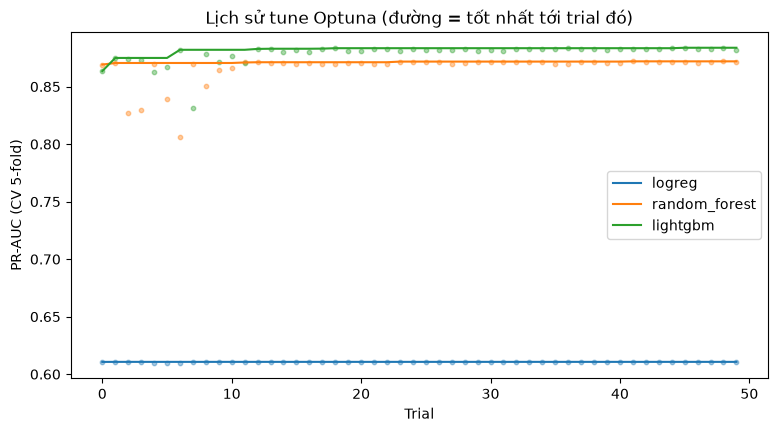

n_estimators         900.000000
learning_rate          0.010968
num_leaves           122.000000
min_child_samples     40.000000
subsample              0.904584
colsample_bytree       0.999686
reg_lambda             0.877812
scale_pos_weight       2.798854
Name: Tham số tốt nhất lightgbm, dtype: float64

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for algo, vals in report["trials_history"].items():
    line = ax.plot(np.maximum.accumulate(vals), label=algo)[0]
    ax.scatter(range(len(vals)), vals, s=10, alpha=0.4, color=line.get_color())
ax.set_xlabel("Trial")
ax.set_ylabel("PR-AUC (CV 5-fold)")
ax.set_title("Lịch sử tune Optuna (đường = tốt nhất tới trial đó)")
ax.legend()
plt.savefig(FIG / "optuna_history.png", dpi=150, bbox_inches="tight")
plt.show()
pd.Series(cand.loc[report["selected"], "best_params"], name=f"Tham số tốt nhất {report['selected']}")

## 2. Kết quả trên tập test và chọn ngưỡng τ

In [4]:
_, _, test = split_data(pd.read_csv(RAW))
y_te = test["Churned"]
p_te = bundle["model"].predict_proba(test.drop(columns="Churned"))[:, 1]

rows = {f"τ = {tau:.3f} (F2 trên val)": metrics(y_te, p_te, tau), "τ = 0,5 (mặc định)": metrics(y_te, p_te, 0.5)}
pd.DataFrame(rows).drop("confusion_matrix").astype(float).round(3)

,τ = 0.186 (F2 trên val),"τ = 0,5 (mặc định)"
roc_auc,0.918,0.918
pr_auc,0.879,0.879
recall,0.858,0.761
precision,0.723,0.876
f1,0.785,0.815
f2,0.827,0.782
brier,0.081,0.081


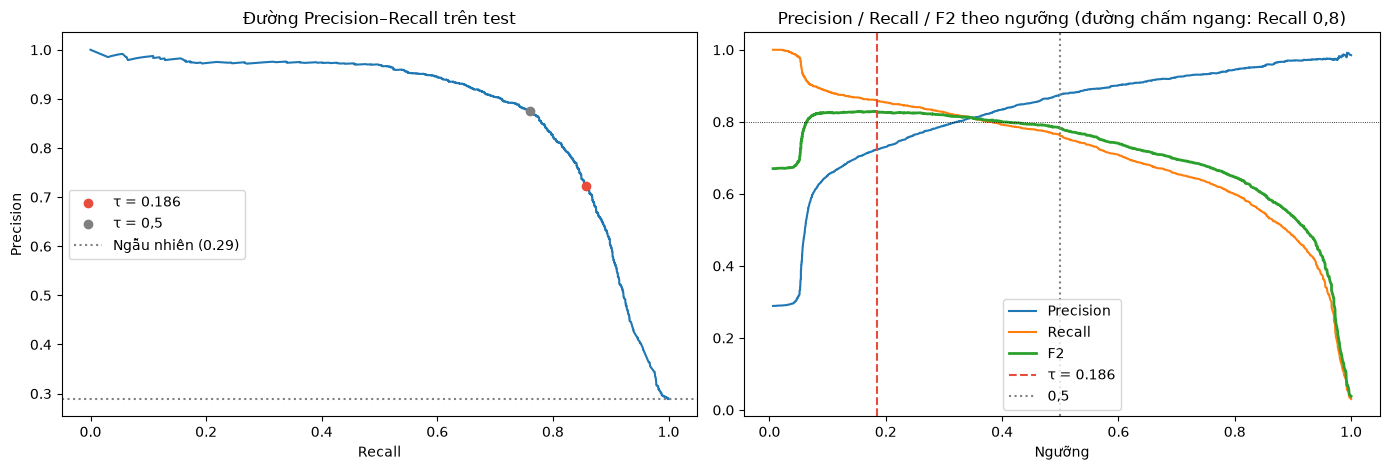

In [5]:
prec, rec, thr = precision_recall_curve(y_te, p_te)
f2 = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)
i_tau, i_05 = np.searchsorted(thr, [tau, 0.5])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8))
a1.plot(rec, prec)
a1.scatter(rec[i_tau], prec[i_tau], color="#e74c3c", zorder=3, label=f"τ = {tau:.3f}")
a1.scatter(rec[i_05], prec[i_05], color="gray", zorder=3, label="τ = 0,5")
a1.axhline(y_te.mean(), ls=":", color="gray", label=f"Ngẫu nhiên ({y_te.mean():.2f})")
a1.set(xlabel="Recall", ylabel="Precision", title="Đường Precision–Recall trên test")
a1.legend()

a2.plot(thr, prec[:-1], label="Precision")
a2.plot(thr, rec[:-1], label="Recall")
a2.plot(thr, f2[:-1], label="F2", lw=2)
a2.axvline(tau, color="#e74c3c", ls="--", label=f"τ = {tau:.3f}")
a2.axvline(0.5, color="gray", ls=":", label="0,5")
a2.axhline(0.8, color="black", lw=0.6, ls=":")
a2.set(xlabel="Ngưỡng", title="Precision / Recall / F2 theo ngưỡng (đường chấm ngang: Recall 0,8)")
a2.legend()
plt.tight_layout()
plt.savefig(FIG / "pr_threshold.png", dpi=150, bbox_inches="tight")
plt.show()

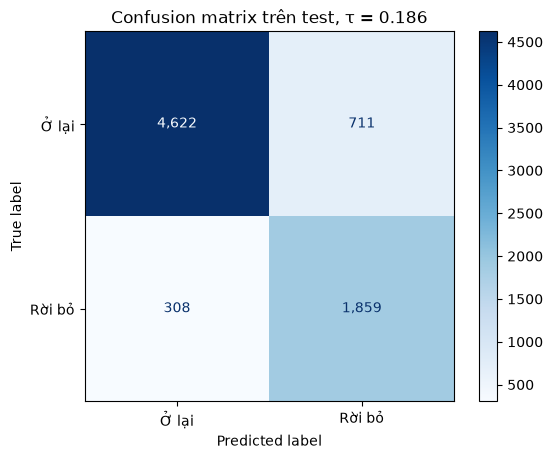

In [6]:
ConfusionMatrixDisplay.from_predictions(y_te, (p_te >= tau).astype(int), display_labels=["Ở lại", "Rời bỏ"],
                                        cmap="Blues", values_format=",")
plt.title(f"Confusion matrix trên test, τ = {tau:.3f}")
plt.savefig(FIG / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Hiệu chỉnh xác suất (calibration)

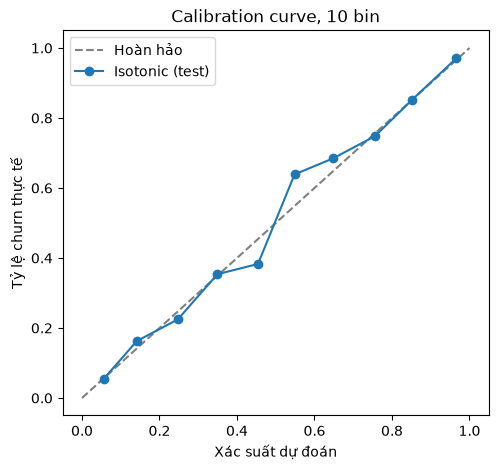

Brier trên test: chưa hiệu chỉnh 0.0876 → isotonic 0.0807


In [7]:
cc = report["calibration_curve"]
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="Hoàn hảo")
ax.plot(cc["mean_pred"], cc["frac_pos"], marker="o", label="Isotonic (test)")
ax.set(xlabel="Xác suất dự đoán", ylabel="Tỷ lệ churn thực tế", title="Calibration curve, 10 bin")
ax.legend()
plt.savefig(FIG / "calibration.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Brier trên test: chưa hiệu chỉnh {report['test_brier_uncalibrated']:.4f} → isotonic {report['test']['brier']:.4f}")

## 4. Yếu tố ảnh hưởng toàn tệp (SHAP)

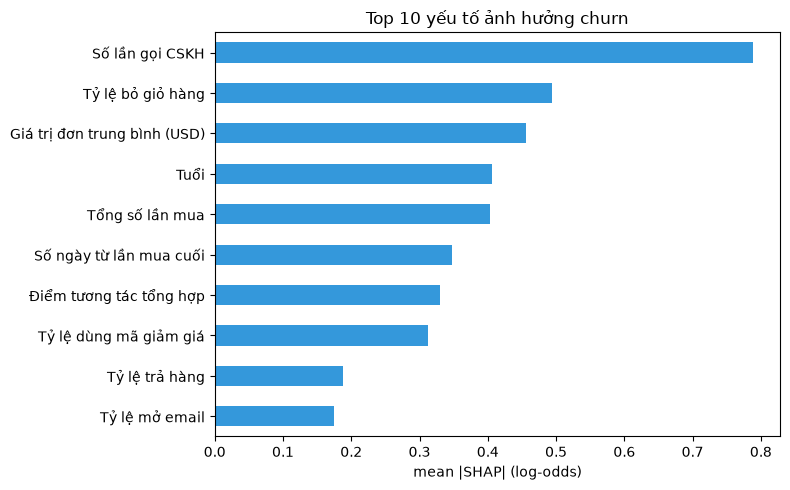

In [8]:
gi = pd.DataFrame(config["global_importance"]).set_index("label")["mean_abs_shap"].sort_values()
ax = gi.plot.barh(figsize=(8, 5), color="#3498db")
ax.set(xlabel="mean |SHAP| (log-odds)", ylabel="", title="Top 10 yếu tố ảnh hưởng churn")
plt.tight_layout()
plt.savefig(FIG / "shap_global.png", dpi=150, bbox_inches="tight")
plt.show()

Biểu đồ beeswarm trên 2.000 khách của tập test: mỗi chấm là một khách, trục ngang là SHAP (log-odds; bên phải
= đẩy p_churn lên), màu là giá trị của feature (đỏ = cao, xanh = thấp, xám = cột phân loại).

D:\WORK\Education\HK07\ML_Project\machine_learning_project\.venv\Lib\site-packages\shap\explainers\_tree.py:620: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


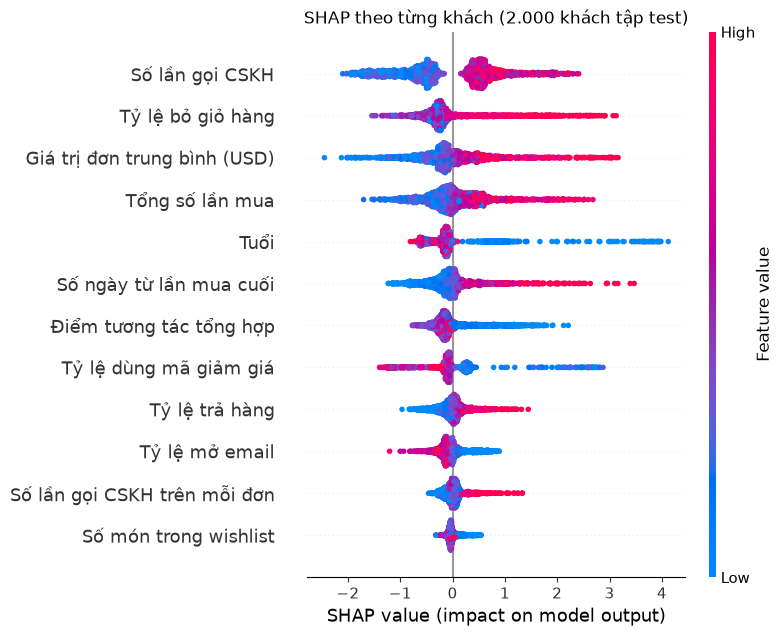

In [9]:
import shap

from ml_engine.src.explain import LABELS, feature_frame, shap_by_source

sample = test.drop(columns="Churned").sample(2000, random_state=42)
sv = shap_by_source(bundle["raw_pipe"], sample)
feat = feature_frame(bundle["raw_pipe"], sample)
values = pd.DataFrame({c: pd.to_numeric(feat[c], errors="coerce") for c in sv.columns}, index=sample.index)
top = sv.abs().mean().sort_values(ascending=False).index[:12]
shap.summary_plot(sv[top].to_numpy(), values[top].to_numpy(), feature_names=[LABELS.get(c, c) for c in top],
                  max_display=12, show=False)
plt.title("SHAP theo từng khách (2.000 khách tập test)")
plt.savefig(FIG / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

**Đọc beeswarm** (bổ sung cho bảng mean |SHAP| — cho biết *chiều* tác động):
- Gọi CSKH nhiều, bỏ giỏ cao, lâu chưa mua lại → đẩy churn lên (khớp EDA mục 8).
- **Khách trẻ** (Tuổi thấp, xanh) có SHAP dương rất lớn ở một nhóm nhỏ — tín hiệu mà tương quan đơn biến (ρ = −0,10) không thấy rõ.
- **Ít dùng mã giảm giá** và **ít mở email** cũng đẩy churn lên; **AOV cao** đẩy churn lên → khách chi nhiều mỗi đơn chưa chắc trung thành.
- Các biến hành vi tương quan mạnh với nhau (EDA mục 7) nên SHAP chia ảnh hưởng giữa chúng; đọc theo nhóm hành vi.
- Đường F2 ở mục 2 gần như phẳng khi τ trong khoảng 0,1–0,35 → kết quả không nhạy với giá trị τ chính xác, đúng như D-14.

## Kết luận

- **Chọn LightGBM**: PR-AUC CV cao nhất; Random Forest sát nút nhưng tune lâu hơn. Logistic Regression thấp hẳn vì quan hệ phi tuyến (notebook 01 mục 6: không feature nào đứng một mình đủ mạnh).
- **Ngưỡng τ chọn theo F2** vì bỏ sót khách sắp rời (FN) đắt hơn gọi nhầm khách ở lại (FP). Với xác suất đã hiệu chỉnh, τ tối ưu F2 thấp hơn 0,5 là đúng lý thuyết (τ* ≈ F2*/5). Bảng mục 2 cho thấy τ = 0,5 làm Recall rơi dưới tiêu chí 0,80 (D-14).
- **Hiệu chỉnh isotonic** giảm Brier và đưa đường calibration sát đường chéo → p_churn dùng được trực tiếp làm r = 1 − p trong CLV.
- Giới hạn: test chỉ đánh giá một lần; dữ liệu tổng hợp nên kết quả có thể lạc quan hơn dữ liệu thật.